In [1]:
from pathlib import Path
from typing import NamedTuple

import numpy as np
from numpy.typing import NDArray
import matplotlib as mpl
import matplotlib.pyplot as plt
from astropy.io.fits import FITS_rec

from bloodmoon.io import simulation_files
from bloodmoon.mask import CodedMaskCamera, codedmask
from bloodmoon.mask import count, decode, variance
from bloodmoon.types import CoordEquatorial
import darksun as ds
from darksun.benchmarking import source_catalogue_data
from darksun.data import DataLoader, CatalogueLoader

plt.rcdefaults()

RCPARAMS = {
    'axes.formatter.limits': (-3, 3),
    'savefig.bbox': 'tight',
}
mpl.rcParams.update(RCPARAMS)

ds.show.set_figures_darkbkg()

In [2]:
class CountListsMap(NamedTuple):
    common: NDArray
    unique: NDArray
    idx_a: NDArray
    idx_b: NDArray

def get_ctsmap_for_lists(
    phlist_A: FITS_rec,
    phlist_B: FITS_rec,
    select_by: str = 'ID',
    uniqueIDs: bool = True,
) -> CountListsMap:
    """
    Finds common count IDs in given photon lists.
    Returns the sorted, unique src IDs that are in both input lists, and the index map.
    """
    ida, idb = phlist_A[select_by], phlist_B[select_by]
    common, idx_a, idx_b = np.intersect1d(ida, idb, assume_unique=uniqueIDs, return_indices=True)
    unique = np.setxor1d(ida, idb, assume_unique=uniqueIDs)
    return CountListsMap(common, unique, idx_a, idx_b)

def get_source_coords(sourceID: str, catalogue: CatalogueLoader) -> CoordEquatorial:
    """Extracts the source RA/Dec coords from catalogue."""
    data = source_catalogue_data(sourceID, catalogue.DLdata)
    return CoordEquatorial(data['RA'], data['DEC'])

def select_target_srcs(
    photons: FITS_rec,
    srcIDs: str | tuple[str, ...],
    catalogue: CatalogueLoader,
) -> FITS_rec:
    """Filters the input photon list for the given sources equatorial coords."""
    srcIDs_ = (srcIDs,) if isinstance(srcIDs, str) else srcIDs
    coords = tuple(get_source_coords(src, catalogue) for src in srcIDs_)
    phs = ds.select_source_photons(coords, photons, False)
    return phs

In [3]:
MASK_FITS: str = "mask_NTHT_20260129_CORRECTED.fits"
SKYFIELD: str = "IROSDummy"
DATA_FITS: str = "baseline_2-50keV_1ks"

ID_CAMERA: str = "cam1a"

E_min: float = 2.0  # [keV]
E_max: float = 4.0  # [keV]

UPS_X, UPS_Y = 1, 1
hide_bulk_els_y: float = 1.5   # [mm]

In [4]:
# BASEDIR: str = "/mnt/dbb8f47e-da06-47bf-8ef5-038092af70f7/Edos_Magnificent_Manor/PhD_AASS/Coding/IROS_Data/Simulations"
BASEDIR: str = "/mnt/d/PhD_AASS/Coding/Images_fits"

DATAPATH: str = f"{BASEDIR}/{SKYFIELD}/{DATA_FITS}/"

In [72]:
wfm: CodedMaskCamera = codedmask(f'{BASEDIR}/{MASK_FITS}', UPS_X, UPS_Y, hide_bulk_els_y=hide_bulk_els_y)

filepaths: dict[str, dict[str, Path]] = simulation_files(DATAPATH)

cat = ds.get_catalogue(filepaths[ID_CAMERA]['sources'])
sdl_detect, sdl_recons = map(
    lambda f: ds.get_data(f, E_min=E_min, E_max=E_max),
    (filepaths[ID_CAMERA]['detected'], filepaths[ID_CAMERA]['reconstructed']),
)

In [73]:
srcID: str = 's17'

phs_detect, phs_recons = map(lambda sdl: np.sort(select_target_srcs(sdl.DLdata, srcID, cat)), (sdl_detect, sdl_recons))
sdd_detect, sdd_recons = map(lambda data: count(wfm, data)[0], (phs_detect, phs_recons))

CATALOG ='IROS_benchmark_catalogue_1ks.fits' / Catalog file                      [astropy.io.fits.card]


UserInfo: using bulk mask of [0.0 x 3] mm.


In [74]:
len_detec, len_recons = map(len, (phs_detect, phs_recons))
len_unq_detec, len_unq_recons = map(lambda x: len(np.unique(x)), (phs_detect['ID'], phs_recons['ID']))

print(
    f'Selected source: {srcID} in ({E_min}, {E_max}) keV\n\n'

    f'  * counts from detected list: {len_detec}\n'
    f'  * counts from reconstructed list: {len_recons}\n'
    f'  * delta counts: {len_detec - len_recons} ({(len_detec - len_recons) * 100 / len_detec:.4f} %)\n\n'

    f'  * repetitions in detected list: {len_detec - len_unq_detec} ({(len_detec - len_unq_detec) / len_detec} %)\n'
    f'  * repetitions in reconstructed list: {len_recons - len_unq_recons} ({(len_recons - len_unq_recons) / len_recons} %)'
)

Selected source: s17 in (2.0, 4.0) keV

  * counts from detected list: 263225
  * counts from reconstructed list: 259459
  * delta counts: 3766 (1.4307 %)

  * repetitions in detected list: 0 (0.0 %)
  * repetitions in reconstructed list: 0 (0.0 %)


In [6]:
axis: str = 'Y'

ctsmap = get_ctsmap_for_lists(phs_detect, phs_recons)
y_det, y_rec = phs_detect[axis][ctsmap.idx_a], phs_recons[axis][ctsmap.idx_b]

axflag = axis == 'Y'
# artfct_mask = (wfm.bulk.sum(axis=int(axflag)) > 0)
mask_eldim = wfm.specs.mask_deltay if axflag else wfm.specs.mask_deltax
mask_pitch = wfm.specs.slit_deltay if axflag else wfm.specs.slit_deltax
bins = wfm.bins_detector.y if axflag else wfm.bins_detector.x

print(f'Analysing {'coarse' if axflag else 'fine'} axis...')

NameError: name 'phs_detect' is not defined

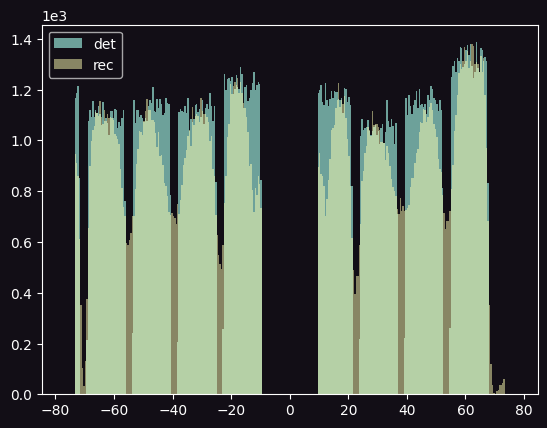

In [ ]:
a, *_ = np.histogram(y_det, wfm.bins_detector.y)
b, *_ = np.histogram(y_rec, wfm.bins_detector.y)

_ = plt.stairs(a, bins, label='det', alpha=0.75, fill=True)  # a * artfct_mask
_ = plt.stairs(b, bins, label='rec', alpha=0.5, fill=True)   # b * artfct_mask
_ = plt.legend()

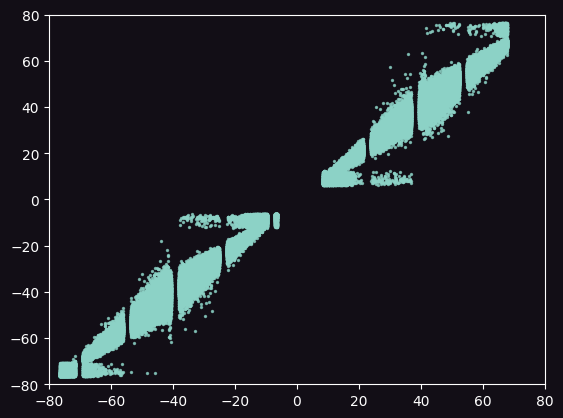

In [ ]:
_ = plt.scatter(y_det, y_rec, alpha=0.75, s=2)
_ = plt.ylim((-80, 80))
_ = plt.xlim((-80, 80))

Bins in [-15.5000, 15.5000] mm (# bins: 201), resolution of 0.1550 mm.


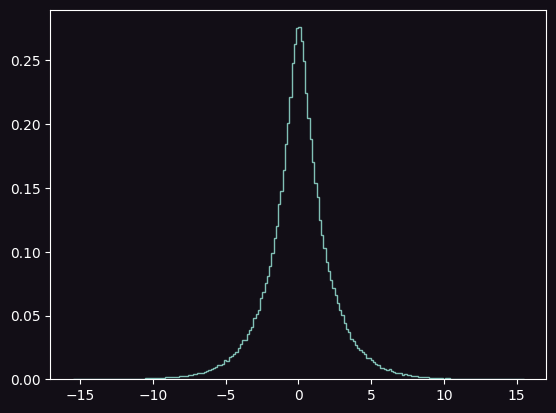

In [ ]:
els_res = mask_eldim / wfm.upscale_f[int(axflag)]
# grade_mask = (src_rec['GRADE'] > 2)

hist_kws = dict(histtype='step', density=True, alpha=0.9)
profile_bins = np.linspace(-mask_pitch, mask_pitch, 2 * int(mask_pitch / els_res) + 1)
_ = plt.hist(y_det - y_rec, profile_bins, **hist_kws)

print(f'Bins in [{-mask_pitch:.4f}, {mask_pitch:.4f}] mm (# bins: {len(profile_bins)}), resolution of {els_res:.4f} mm.')